In [79]:
from WF4Py import waveforms as WF;
from WF4Py import WFutils as utils;

import numpy as np
from astropy.cosmology import Planck18

import pycbc.conversions as cvs;
import pycbc.waveform as wf;
import pycbc.types as tps;

import time
import sys
import os

import matplotlib.pyplot as pp
from matplotlib import gridspec
from matplotlib import rc
rc('text', usetex=False)


ourcodenameString = 'WF4Py'

In [80]:
import numpy as np
# 双精度浮点数（Python float 类型）的机器epsilon
eps = np.finfo(np.float64).eps
print(eps)  # 输出约 2.220446049250313e-16

2.220446049250313e-16


In [81]:
zs = np.array([.2, .5, .7])

# events0 = {'Mc':np.array([30, 45, 60])*(1.+zs),
#           'dL':(Planck18.luminosity_distance(zs).value/1000.),
#           'iota':np.array([.0, .4, np.pi]),
#           'eta':np.array([0.24, .23, .2499]),
#           'chi1z':np.array([0.8, .5, 0.]),
#           'chi2z':np.array([-0.8, 0., -.2]),

#           'f_lower': np.array([15]),}

events = {'Mc':np.array([cvs.mchirp_from_mass1_mass2(33,12)]),
          'dL':np.array([137]),
          'iota':np.array([0*np.pi]),
          'eta':np.array([cvs.eta_from_mass1_mass2(33,12)]),
          'chi1z':np.array([0.8]),
          'chi2z':np.array([0.57]),
          'f_lower': np.array([100]),
          'f_final': np.array([2048])}

# Note that this model has various versions for both the phase and the amplitude
tmpWF = WF.IMRPhenomXAS(InsPhaseVersion=104, IntPhaseVersion=105, IntAmpVersion=104)

fcut = tmpWF.fcut(**events)
# fcut = tmpWF.fcut(**events)
fminarr = np.full(fcut.shape, 5)
fgrids = np.geomspace(fminarr, fcut, num=int(1000))

myampl = tmpWF.Ampl(fgrids, **events)
myphase = tmpWF.Phi(fgrids, **events)
originphase = tmpWF.Phi0(fgrids, **events)

[0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 

In [82]:
events = dict(
    mass1 = 33,
    mass2 = 12,
    spin1z = 0.8,
    spin2z = 0.57,
    distance = 0.137,
    # inclination = -np.pi/3,
    inclination = 0,
    coa_phase = 12.0,

    f_lower = 100,
    delta_f = 1/16,
    f_final = 2048,
)

tmpWF = WF.IMRPhenomXAS()
fcut = tmpWF.fcut(**events|{"Mc": np.array([cvs.mchirp_from_mass1_mass2(events['mass1'],events['mass2'])]), "eta": np.array([cvs.eta_from_mass1_mass2(events['mass1'],events['mass2'])])})
fminarr = np.full(fcut.shape, events["f_lower"])
delta_f = events["delta_f"]
fgrids = np.arange(fminarr, fcut, delta_f)
fgrids = fgrids.reshape(-1, 1)

hp1, hc1 = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    # f_ref = 100,
                                                    if_dchi0=False,
                                                    if_dchi1=False,
                                                    if_dchi2=False,
                                                    if_dchi3=False,
                                                    if_dchi4=False,
                                                    if_dchi5l=False,
                                                    if_dchi5=False,
                                                    if_dchi6=False,
                                                    if_dchi6l=False,
                                                    if_dchi7=False,
                                                    if_dchi8=False,
                                                    if_dchi8l=False,
                                                    )

[0.]
[0. 0. 0. ... 0. 0. 0.]


/tmp/ipykernel_4008426/694864834.py:20: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  fgrids = np.arange(fminarr, fcut, delta_f)


In [83]:

hp2, hc2 = wf.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"]
                                                    )

hp2_dchi3, hc2_dchi3 = wf.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    dchi3 = 10,
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"]
                                                    )

hp2_dchi4, hc2_dchi4 = wf.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    dchi4 = 10,
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"]
                                                    )

[32.80206668]
[43.88719477 43.88026656 43.87333836 ... 26.35190777 26.34497957
 26.33805136]


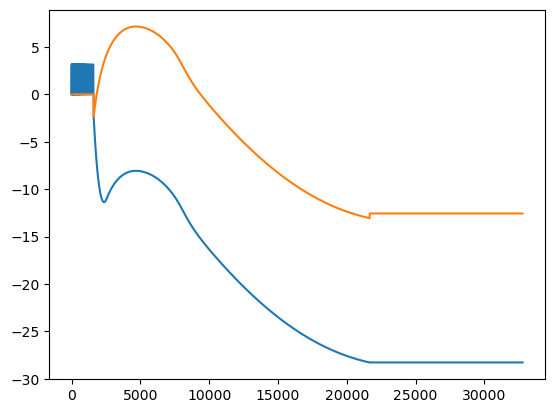

In [129]:
hp2_dchi3, hc2_dchi3 = wf.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    dchi3 = 0,
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"]
                                                    )

hp1_dchi3, hc1_dchi3 = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    dchi3=-394.1458689399577*(1+10),
                                                    if_dchi0=False,
                                                    if_dchi1=False,
                                                    if_dchi2=False,
                                                    if_dchi3=True,
                                                    if_dchi4=False,
                                                    if_dchi5l=False,
                                                    if_dchi5=False,
                                                    if_dchi6=False,
                                                    if_dchi6l=False,
                                                    if_dchi7=False,
                                                    if_dchi8=False,
                                                    if_dchi8l=False,
                                                    )

pp.plot(np.unwrap(np.angle(hp1_dchi3.data)))
pp.plot(np.unwrap(np.angle(hp2_dchi3.data)))

In [130]:
np.sum(np.conj(hp1_dchi3.data)*hp2_dchi3.data[:len(hp1_dchi3.data)]) / np.sum((np.conj(hp2_dchi3.data[:len(hp1_dchi3.data)])*hp2_dchi3.data[:len(hp1_dchi3.data)]))

(-0.5013330826017177+0.3542670509726344j)

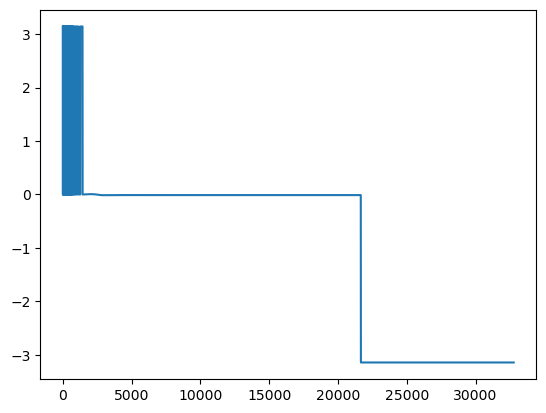

In [116]:
pp.plot(np.unwrap(np.angle(hp1_dchi3.data)) - np.unwrap(np.angle(hp2_dchi3.data))[:len(hp1_dchi3.data)])
# pp.plot()

In [76]:
hp1_dchi4, hc1_dchi4 = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    dchi4=20.11334056036653*(1 + 280),
                                                    if_dchi0=False,
                                                    if_dchi1=False,
                                                    if_dchi2=False,
                                                    if_dchi3=False,
                                                    if_dchi4=True,
                                                    if_dchi5l=False,
                                                    if_dchi5=False,
                                                    if_dchi6=False,
                                                    if_dchi6l=False,
                                                    if_dchi7=False,
                                                    if_dchi8=False,
                                                    if_dchi8l=False,
                                                    )

hp2_dchi4, hc2_dchi4 = wf.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    dchi4 = 100,
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"]
                                                    )

[-228.56744313]
[-271.41390963 -271.38713059 -271.36035155 ... -203.63615543 -203.60937639
 -203.58259734]


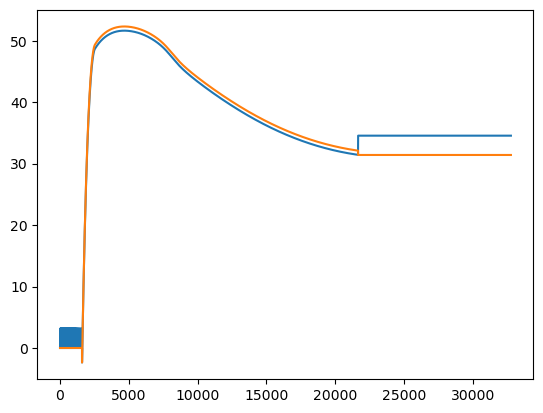

In [77]:
pp.plot(np.unwrap(np.angle(hp1_dchi4.data)))
pp.plot(np.unwrap(np.angle(hp2_dchi4.data)))

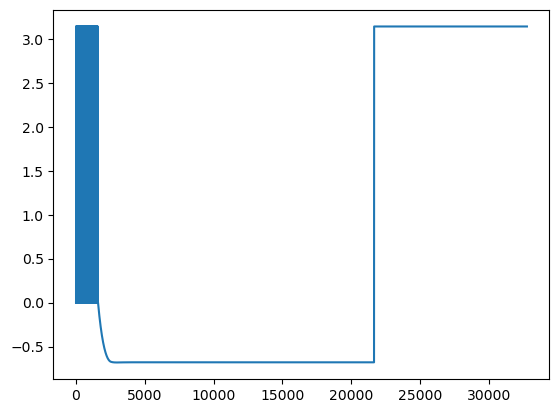

In [78]:
pp.plot(np.unwrap(np.angle(hp1_dchi4.data))-np.unwrap(np.angle(hp2_dchi4.data[:len(hp1_dchi4.data)])))

In [43]:
1 - np.sum(np.conj(hp1.data)*hp2.data[:32768])/np.sum(np.conj(hp2.data)*hp2.data)

(4.223703391303957e-05-0.0047831273794507155j)

In [44]:
1 - np.sum(np.conj(hp1_dchi3.data)*hp2.data[:32768])/np.sum(np.conj(hp2.data)*hp2.data)

(1.5013330826023203-0.3542670509717219j)

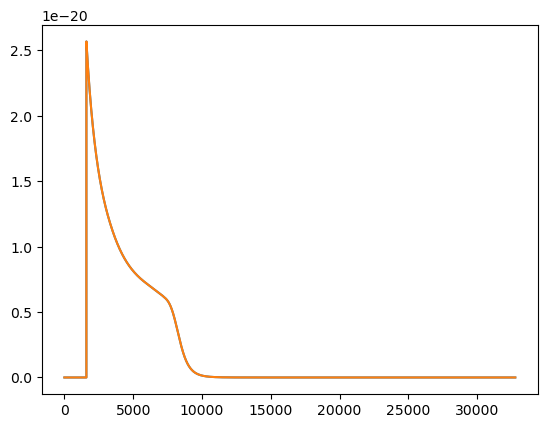

In [46]:
pp.plot(np.abs(hp1.data))
pp.plot(np.abs(hp2.data))

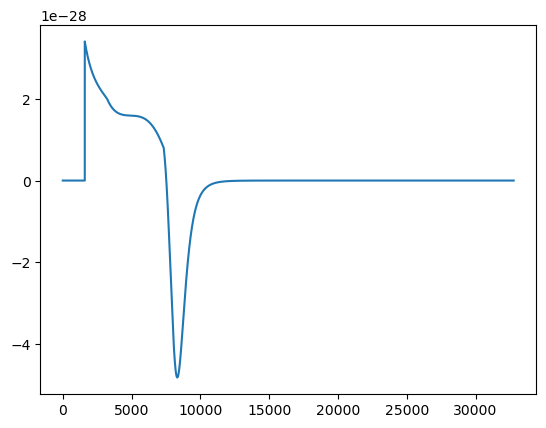

In [47]:
pp.plot(np.abs(hp1.data)-np.abs(hp2.data)[:32768])
# pp.plot()

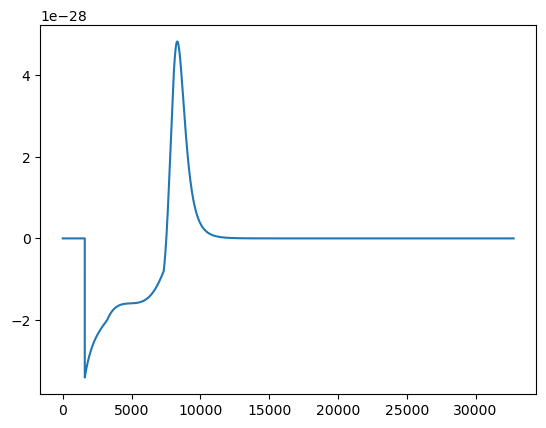

In [48]:
pp.plot(np.abs(hp2.data)[:32768]-np.abs(hp1_dchi3.data))

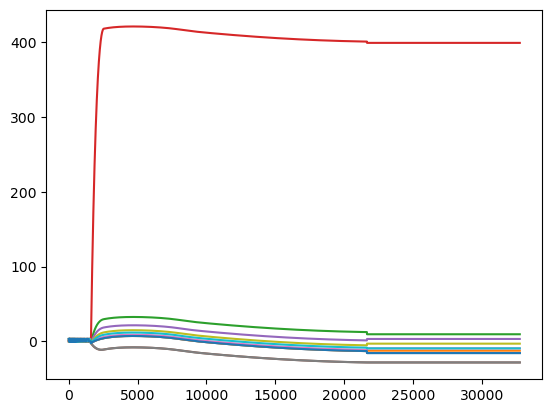

In [49]:
pp.plot(np.unwrap(np.angle(hp1.data)))
pp.plot(np.unwrap(np.angle(hp2.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi0.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi1.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi2.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi3.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi4.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi6.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi6l.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi5l.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi7.data)))
# pp.xlim([15000,20000])
# pp.ylim([240,250])

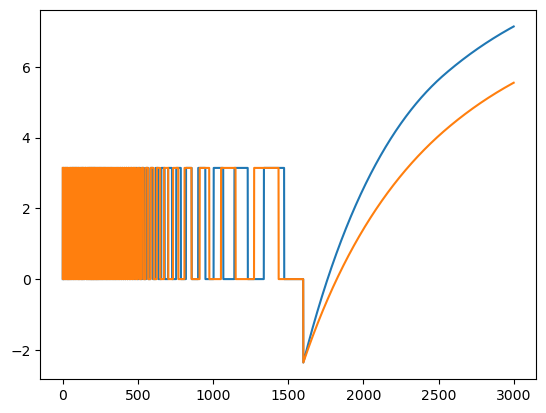

In [50]:
pp.plot(np.unwrap(np.angle(hp1_dchi4.data))[:3000])
pp.plot(np.unwrap(np.angle(hp1.data))[:3000])

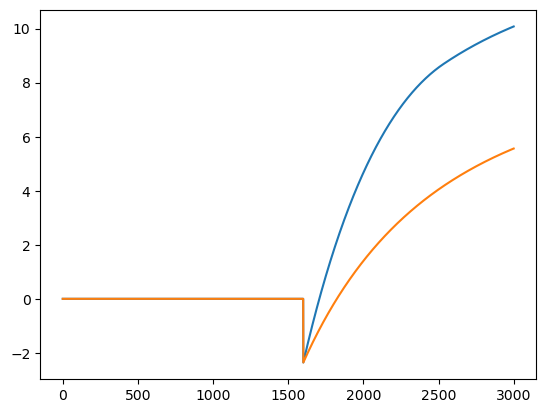

In [51]:
pp.plot(np.unwrap(np.angle(hp2_dchi4.data))[:3000])
pp.plot(np.unwrap(np.angle(hp2.data))[:3000])

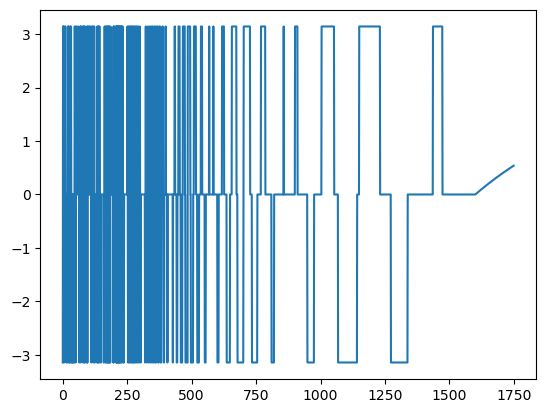

In [52]:
pp.plot((np.unwrap(np.angle(hp1_dchi4.data)) - np.unwrap(np.angle(hp1.data)))[:1750])

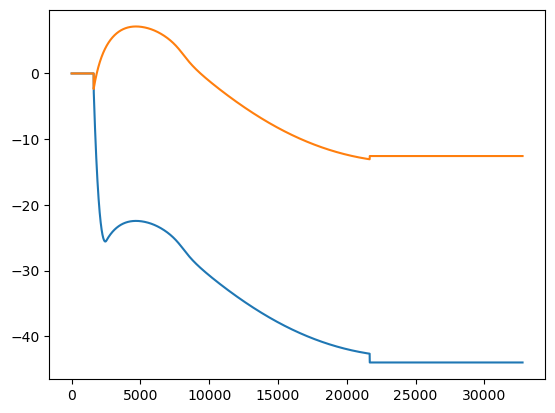

In [53]:
pp.plot(np.unwrap(np.angle(hp2_dchi3.data)))
pp.plot(np.unwrap(np.angle(hp2.data)))

In [11]:
pp.plot(np.unwrap(np.angle(hp2_dchi3.data))-np.unwrap(np.angle(hp2.data)))


NameError: name 'hp2_dchi1' is not defined

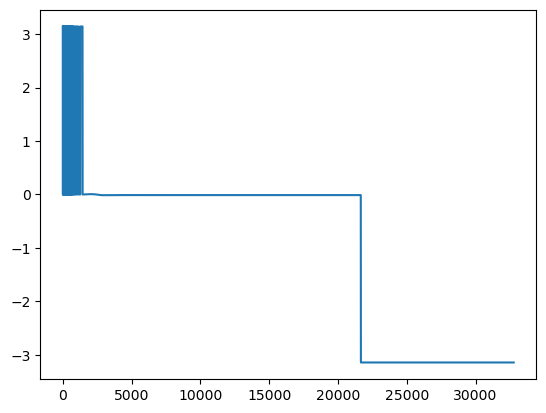

In [10]:
pp.plot(np.unwrap(np.angle(hp1.data))-np.unwrap(np.angle(hp2.data[:len(hp1.data)])))
# pp.xlim([0,250])
# pp.xlim([300, 10000])

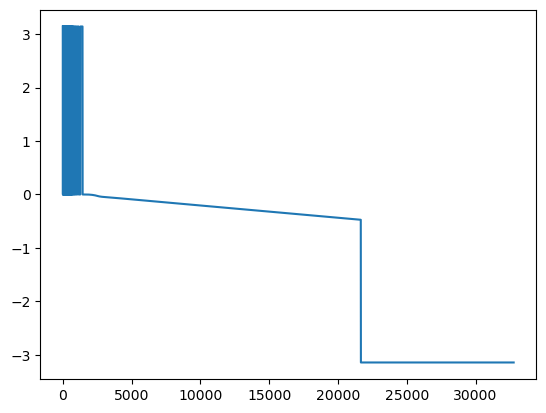

In [9]:
pp.plot(np.unwrap(np.angle(hp1_dchi7.data))-np.unwrap(np.angle(hp2.data[:len(hp1.data)])))

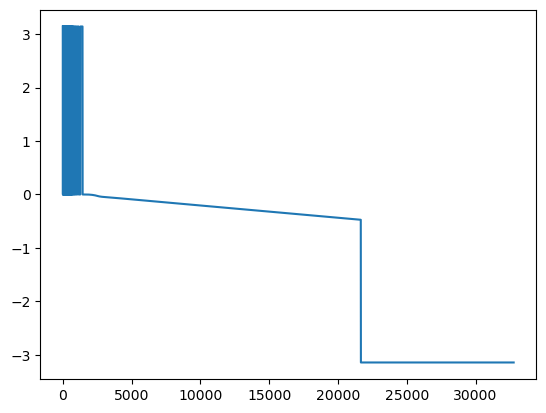

In [13]:
pp.plot(np.unwrap(np.angle(hp1_dchi7.data))-np.unwrap(np.angle(hp2.data[:len(hp1.data)])))

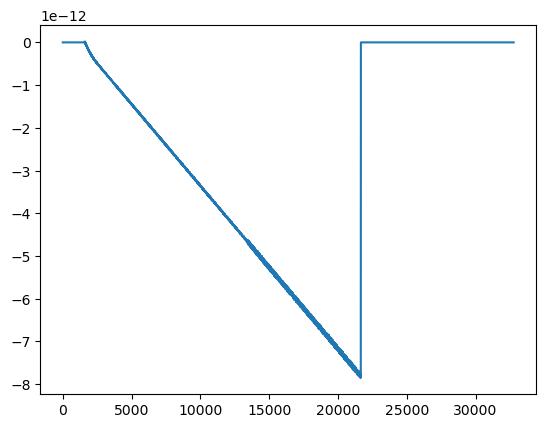

In [32]:
pp.plot(np.unwrap(np.angle(hp1_dchi3.data))-np.unwrap(np.angle(hp1.data)))

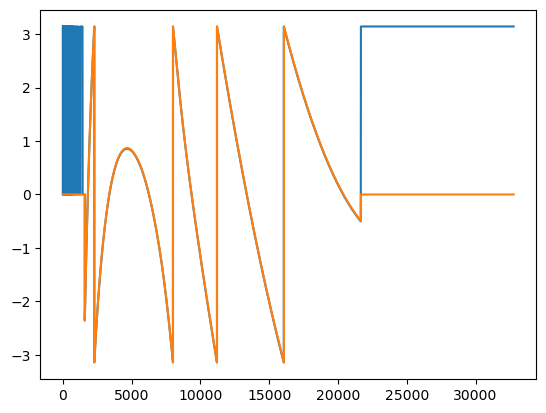

In [33]:
pp.plot(np.angle(hp1.data))
pp.plot(np.angle(hp2.data[:len(hp1.data)]))
# pp.xlim([0,1000])

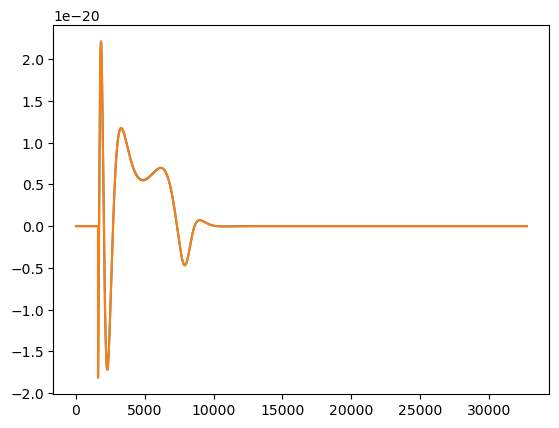

In [34]:
pp.plot(hp1)
pp.plot(hp2)

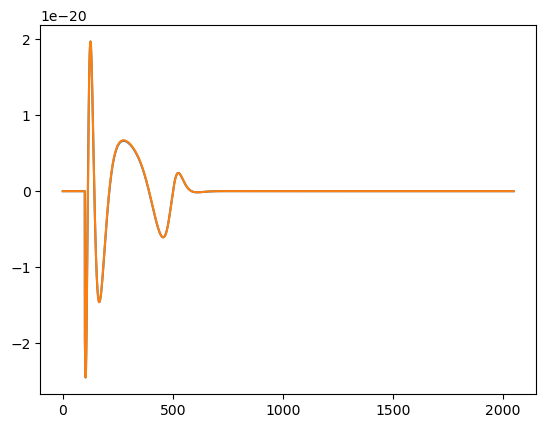

In [35]:
pp.plot(hp1.sample_frequencies, np.imag(hp1.data))
pp.plot(hp2.sample_frequencies, np.imag(hp2.data))

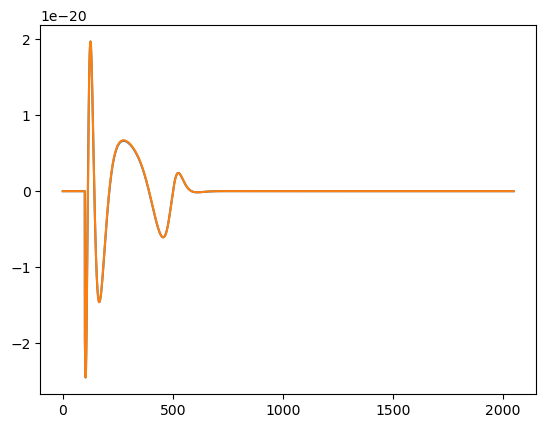

In [36]:
pp.plot(hp1.sample_frequencies, np.real(hc1.data))
pp.plot(hp2.sample_frequencies, np.real(hc2.data))

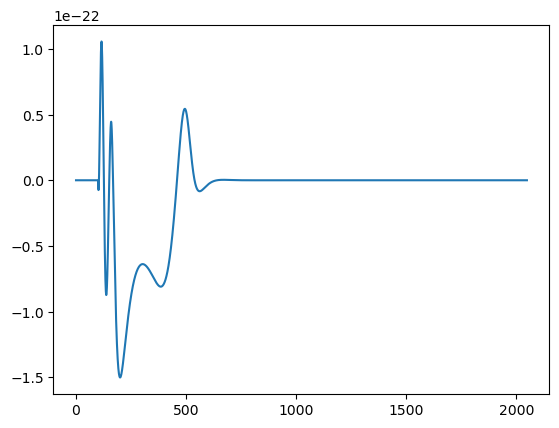

In [37]:
pp.plot(hp1.sample_frequencies, np.real(hc1.data)-np.real(hc2.data[:len(hc1.data)]))


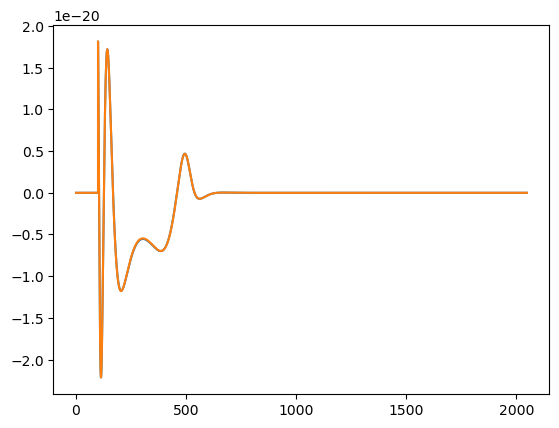

In [38]:
pp.plot(hp1.sample_frequencies, np.imag(hc1.data))
pp.plot(hp2.sample_frequencies, np.imag(hc2.data))

(0.0, 300.0)

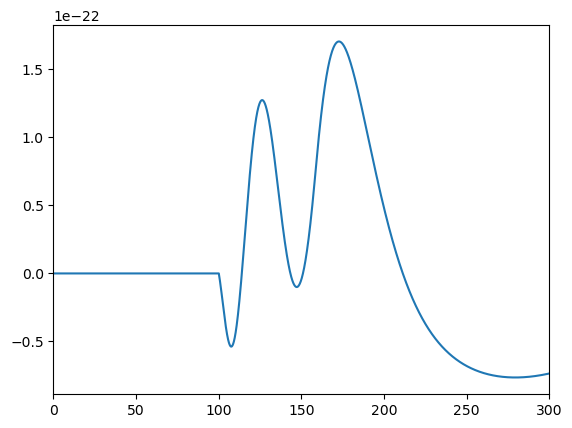

In [40]:
pp.plot(hp1.sample_frequencies, np.imag(hc1.data)-np.imag(hc2.data[:len(hc1.data)]))
pp.xlim([0, 300])
# pp.plot(hp2.sample_frequencies, )